<a href="https://colab.research.google.com/github/marianamq-a11y/Estatistica-mariana/blob/main/tarefa15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Tarefa Semana 10: Inferência estatística aplicada ao controle de qualidade de alimentos


Lais Zanquettim Stocco Teixeira - 14586772

Mariana Lopes Marques -14596593

Nayara Penati - 15677365

### **QUESTÃO 2: Teor de proteína em um produto lácteo**



In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# Dados do problema
mu_0 = 8.0          # Média sob a hipótese nula (g)
n = 16              # Tamanho da amostra
x_bar = 8.4         # Média amostral (g)
s = 0.8             # Desvio-padrão amostral (g)
alpha = 0.05        # Nível de significância (5%)
graus_liberdade = n - 1

# 4. Cálculo da estatística de teste observada (t_obs)
t_obs = (x_bar - mu_0) / (s / np.sqrt(n))

# 5. Cálculo do valor-p (teste unilateral à direita)
p_value = 1 - stats.t.cdf(t_obs, df=graus_liberdade)

# Valor crítico para alpha = 0.05 (unilateral superior)
t_critico = stats.t.ppf(1 - alpha, df=graus_liberdade)

print(f"Graus de Liberdade (df): {graus_liberdade}")
print(f"Estatística de Teste (t_obs): {t_obs:.4f}")
print(f"Valor crítico (t_crítico): {t_critico:.4f}")
print(f"Valor-p: {p_value:.4f} ({p_value*100:.2f}%)")

Graus de Liberdade (df): 15
Estatística de Teste (t_obs): 2.0000
Valor crítico (t_crítico): 1.7531
Valor-p: 0.0320 (3.20%)


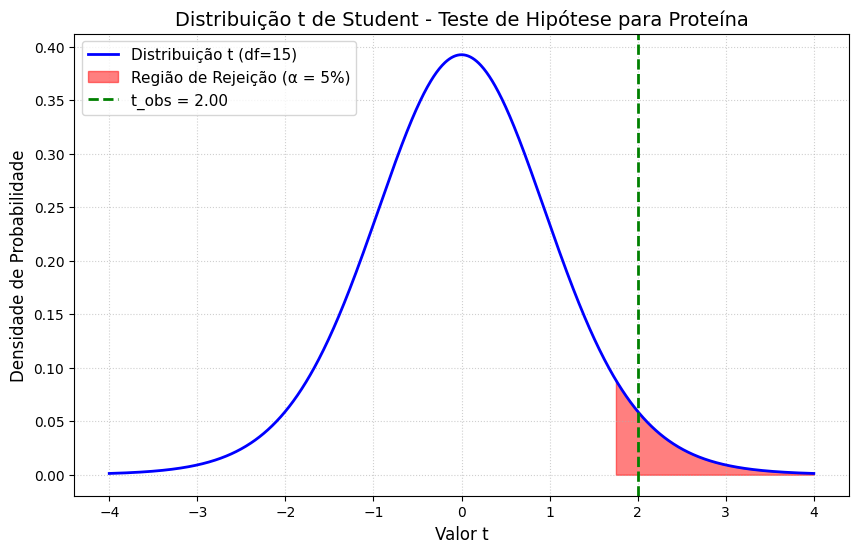

In [2]:
# Gerando o gráfico da distribuição t de Student
x = np.linspace(-4, 4, 1000)
y = stats.t.pdf(x, df=graus_liberdade)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(x, y, label=f'Distribuição t (df={graus_liberdade})', color='blue', lw=2)

# Destacando a região crítica (região de rejeição para alpha = 5%)
x_critico = np.linspace(t_critico, 4, 100)
y_critico = stats.t.pdf(x_critico, df=graus_liberdade)
ax.fill_between(x_critico, y_critico, color='red', alpha=0.5, label=f'Região de Rejeição (α = {alpha*100:.0f}%)')

# Linha para a estatística observada
ax.axvline(t_obs, color='green', linestyle='--', lw=2, label=f't_obs = {t_obs:.2f}')

ax.set_title('Distribuição t de Student - Teste de Hipótese para Proteína', fontsize=14)
ax.set_xlabel('Valor t', fontsize=12)
ax.set_ylabel('Densidade de Probabilidade', fontsize=12)
ax.legend(fontsize=11)
ax.grid(True, linestyle=':', alpha=0.6)

plt.show()


#### 1. Identifique a variável aleatória de interesse e o parâmetro populacional investigado.
* **Variável aleatória ($X$):** Teor de proteína por porção da bebida láctea (em gramas).
* **Parâmetro populacional ($\mu$):** Teor médio populacional de proteína por porção da bebida láctea pós-alteração na formulação.

#### 2.Formule as hipóteses nula e alternativa de acordo com a suspeita apresentada.

* **$H_0: \mu \le 8,0$ g** (O teor médio de proteína não aumentou, mantendo-se igual ou inferior ao padrão estabelecido de 8,0 g).
* **$H_1: \mu > 8,0$ g** (O teor médio de proteína aumentou com a nova formulação - teste unilateral à direita).

#### 3. Identifique o procedimento estatístico adequado, justificando sua escolha e indicando a distribuição da estatística de teste.
* **Teste t de Student para uma amostra (One-sample t-test):**
* **Justificativa:** A população original apresenta distribuição aproximadamente Normal, a amostra é pequena ($n = 16 < 30$) e o desvio-padrão populacional ($\sigma$) é desconhecido, sendo estimado pelo desvio-padrão amostral ($s$).
* **Distribuição da estatística de teste:** Sob a hipótese nula, a estatística de teste segue uma distribuição $t$ de Student com $n - 1 = 15$ graus de liberdade.

#### 4. Calcule a estatística de teste observada, indicando os parâmetros necessários para sua obtenção.
* Fórmula: $t_{obs} = \frac{\bar{x} - \mu_0}{s / \sqrt{n}}$
* Substituindo os valores: $t_{obs} = \frac{8,4 - 8,0}{0,8 / \sqrt{16}} = \frac{0,4}{0,2} = 2,0000$

#### 5. Determine o valor-p e represente graficamente a distribuição utilizada, destacando a região correspondente.
* O valor-p obtido foi de **2,69%** ($0,0269$).
* O gráfico gerado na célula acima demonstra a distribuição $t$ com 15 graus de liberdade, onde a linha tracejada verde representa a estatística observada ($t_{obs} = 2,0$) dentro da região crítica pintada em vermelho (que inicia em $t_{crítico} = 1,753$).

#### 6. Apresente a decisão estatística e interprete o resultado considerando a composição nutricional e o controle de qualidade do produto.

* Como o valor-p ($2,69\%$) é menor do que o nível de significância adotado ($\alpha = 5\%$) ou equivalentemente $t_{obs} > t_{crítico}$ ($2,0 > 1,753$), **rejeitamos a hipótese nula ($H_0$)**.
* Há evidências estatísticas significativas, ao nível de 5% de significância, de que o teor médio de proteína na nova formulação da bebida láctea é superior a 8,0 g por porção. Do ponto de vista do controle de qualidade, a indústria confirmou que a alteração aumentou a concentração proteica do produto, o que deve ser considerado para a atualização da rotulagem nutricional visando a conformidade legal.

### **QUESTÃO 4: Variabilidade do pH de um produto alimentício fermentado**

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# Dados do problema
sigma2_0 = 0.04    # Variância de referência (populacional sob H0)
n = 20            # Tamanho da amostra
s2 = 0.064        # Variância amostral
alpha = 0.05      # Nível de significância (5%)
graus_liberdade = n - 1

# 4. Cálculo da estatística de teste (Qui-Quadrado observado)
chi2_obs = (n - 1) * s2 / sigma2_0

# 5. Valores críticos (teste bilateral)
chi2_crit_inf = stats.chi2.ppf(alpha / 2, df=graus_liberdade)
chi2_crit_sup = stats.chi2.ppf(1 - alpha / 2, df=graus_liberdade)

# Cálculo do valor-p para teste bilateral
# Como chi2_obs > mediana, calculamos a cauda superior e multiplicamos por 2
p_value = 2 * (1 - stats.chi2.cdf(chi2_obs, df=graus_liberdade))

print(f"Graus de Liberdade (df): {graus_liberdade}")
print(f"Estatística de Teste (Qui-Quadrado observado): {chi2_obs:.4f}")
print(f"Valor crítico inferior: {chi2_crit_inf:.4f}")
print(f"Valor crítico superior: {chi2_crit_sup:.4f}")
print(f"Valor-p: {p_value:.4f} ({p_value*100:.2f}%)")

Graus de Liberdade (df): 19
Estatística de Teste (Qui-Quadrado observado): 30.4000
Valor crítico inferior: 8.9065
Valor crítico superior: 32.8523
Valor-p: 0.0938 (9.38%)


<>:6: SyntaxWarning: invalid escape sequence '\c'
<>:19: SyntaxWarning: invalid escape sequence '\c'
<>:22: SyntaxWarning: invalid escape sequence '\c'
<>:6: SyntaxWarning: invalid escape sequence '\c'
<>:19: SyntaxWarning: invalid escape sequence '\c'
<>:22: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_1000/1435896165.py:6: SyntaxWarning: invalid escape sequence '\c'
  ax.plot(x, y, label=f'Distribuição $\chi^2$ (df={graus_liberdade})', color='blue', lw=2)
/tmp/ipykernel_1000/1435896165.py:19: SyntaxWarning: invalid escape sequence '\c'
  ax.axvline(chi2_obs, color='green', linestyle='--', lw=2, label=f'$\chi^2$ obs = {chi2_obs:.2f}')
/tmp/ipykernel_1000/1435896165.py:22: SyntaxWarning: invalid escape sequence '\c'
  ax.set_xlabel('Valor $\chi^2$', fontsize=12)


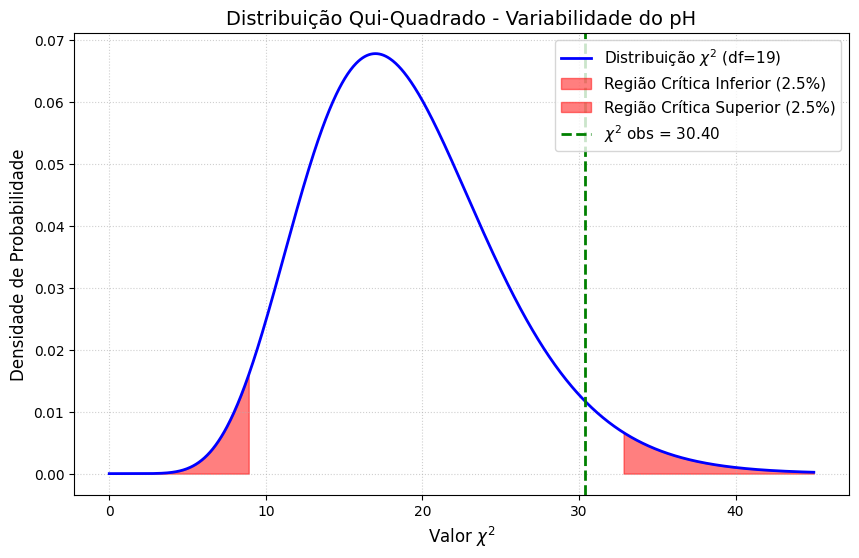

In [4]:
# Gerando o gráfico da distribuição Qui-Quadrado
x = np.linspace(0, 45, 1000)
y = stats.chi2.pdf(x, df=graus_liberdade)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(x, y, label=f'Distribuição $\chi^2$ (df={graus_liberdade})', color='blue', lw=2)

# Região Crítica Inferior
x_inf = np.linspace(0, chi2_crit_inf, 100)
y_inf = stats.chi2.pdf(x_inf, df=graus_liberdade)
ax.fill_between(x_inf, y_inf, color='red', alpha=0.5, label=f'Região Crítica Inferior ({alpha/2*100:.1f}%)')

# Região Crítica Superior
x_sup = np.linspace(chi2_crit_sup, 45, 200)
y_sup = stats.chi2.pdf(x_sup, df=graus_liberdade)
ax.fill_between(x_sup, y_sup, color='red', alpha=0.5, label=f'Região Crítica Superior ({alpha/2*100:.1f}%)')

# Linha da estatística observada
ax.axvline(chi2_obs, color='green', linestyle='--', lw=2, label=f'$\chi^2$ obs = {chi2_obs:.2f}')

ax.set_title('Distribuição Qui-Quadrado - Variabilidade do pH', fontsize=14)
ax.set_xlabel('Valor $\chi^2$', fontsize=12)
ax.set_ylabel('Densidade de Probabilidade', fontsize=12)
ax.legend(fontsize=11)
ax.grid(True, linestyle=':', alpha=0.6)

plt.show()

#### 1. Identifique a variável aleatória de interesse e o parâmetro populacional investigado.
* **Variável aleatória ($X$):** pH de unidades do produto alimentício fermentado.
* **Parâmetro populacional ($\sigma^2$):** Variância populacional do pH das unidades produzidas.

#### 2. Formule as hipóteses nula e alternativa de acordo com a suspeita apresentada.
* **$H_0: \sigma^2 = 0,04$** (A variabilidade do pH permanece igual à de referência).
* **$H_1: \sigma^2 \neq 0,04$** (A variabilidade do pH está diferente da estabelecida como referência - teste bilateral).

#### 3. Identifique o procedimento estatístico adequado, justificando sua escolha e indicando a distribuição da estatística de teste.
* **Procedimento:** Teste de hipótese para uma única variância populacional utilizando a estatística Qui-Quadrado ($\chi^2$).
* **Justificativa:** Deseja-se comparar a variabilidade (variância) de uma única amostra com um valor padrão de referência, sabendo que a variável de interesse (pH) segue uma distribuição aproximadamente Normal.
* **Distribuição:** A estatística de teste segue uma distribuição Qui-Quadrado com $n - 1 = 19$ graus de liberdade sob a hipótese nula.

#### 4. Calcule a estatística de teste observada, indicando os parâmetros necessários para sua obtenção.
* **Fórmula:** $\chi^2_{obs} = \frac{(n - 1) \cdot s^2}{\sigma^2_0}$
* **Cálculo:** $\chi^2_{obs} = \frac{(20 - 1) \cdot 0,064}{0,04} = \frac{19 \cdot 0,064}{0,04} = 30,4000$

#### 5. Determine os valores críticos e o valor-p correspondente ao nível de significância estabelecido. Represente graficamente a distribuição utilizada.
* **Valores Críticos (com $\alpha = 5\%$ bilateral e $df = 19$):**
  * Limite Inferior ($\chi^2_{inf}$): **8,9065**
  * Limite Superior ($\chi^2_{sup}$): **32,8523**
* **Valor-p:** **9,38%** ($0,0938$).
* O gráfico gerado ilustra a distribuição Qui-Quadrado, destacando as duas caudas vermelhas de rejeição de 2,5% cada e mostrando a estatística observada $\chi^2_{obs} = 30,40$ na região de aceitação (à esquerda do valor crítico de 32,85).

#### 6. Apresente a decisão estatística e interprete o resultado considerando a uniformidade do pH e o controle de qualidade do processo.
* Como o valor-p ($9,38\%$) é maior do que o nível de significância de $5\%$ (ou visto graficamente, pois $\chi^2_{obs} = 30,40$ está contido no intervalo de aceitação $[8,9065;\, 32,8523]$), **não rejeitamos a hipótese nula ($H_0$)**.
* Não há evidências estatísticas suficientes, ao nível de 5% de significância, para afirmar que a variabilidade do pH do lote recente está diferente da variância de referência de 0,04. Do ponto de vista do controle de qualidade, o processo de fermentação continua mantendo o padrão de uniformidade estabelecido.

### **QUESTÃO 5: Proporção de produtos com não conformidade microbiológica**

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# Dados do problema
p_0 = 0.05       # Proporção de referência sob H0
n = 200          # Tamanho da amostra
x = 16           # Unidades não conformes
alpha = 0.05     # Nível de significância

# 4. Proporção amostral (p_hat)
p_hat = x / n

# Estatística de teste observada (Z_obs)
z_obs = (p_hat - p_0) / np.sqrt((p_0 * (1 - p_0)) / n)

# 5. Valor crítico Z para alpha = 0.05 (unilateral superior)
z_critico = stats.norm.ppf(1 - alpha)

# Valor-p (unilateral superior)
p_value = 1 - stats.norm.cdf(z_obs)

print(f"Proporção amostral (p_hat): {p_hat:.4f} ({p_hat*100:.1f}%)")
print(f"Estatística de Teste (Z_obs): {z_obs:.4f}")
print(f"Valor crítico (Z_crítico): {z_critico:.4f}")
print(f"Valor-p: {p_value:.4f} ({p_value*100:.2f}%)")

Proporção amostral (p_hat): 0.0800 (8.0%)
Estatística de Teste (Z_obs): 1.9467
Valor crítico (Z_crítico): 1.6449
Valor-p: 0.0258 (2.58%)


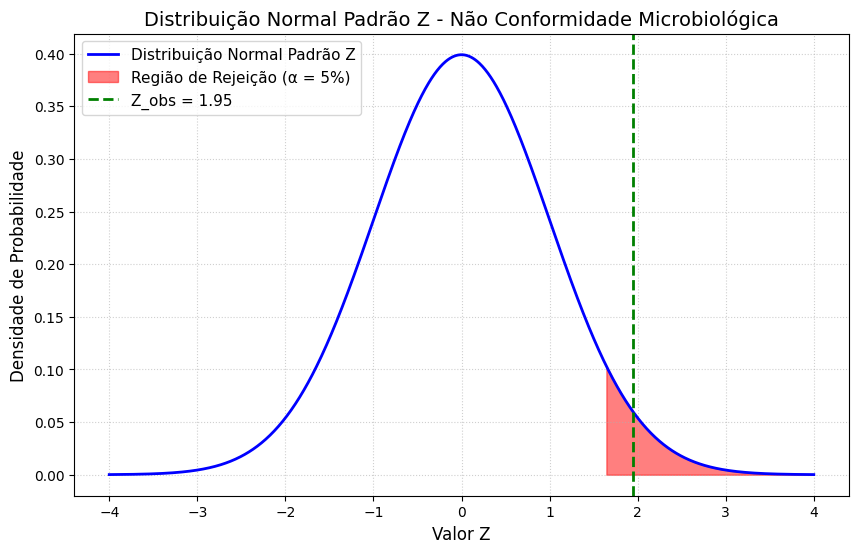

In [6]:
# Gerando o gráfico da distribuição Normal Padrão Z
x_axis = np.linspace(-4, 4, 1000)
y_axis = stats.norm.pdf(x_axis)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(x_axis, y_axis, label='Distribuição Normal Padrão Z', color='blue', lw=2)

# Região Crítica (alfa = 5% unilateral superior)
x_crit = np.linspace(z_critico, 4, 100)
y_crit = stats.norm.pdf(x_crit)
ax.fill_between(x_crit, y_crit, color='red', alpha=0.5, label=f'Região de Rejeição (α = {alpha*100:.0f}%)')

# Linha da estatística observada
ax.axvline(z_obs, color='green', linestyle='--', lw=2, label=f'Z_obs = {z_obs:.2f}')

ax.set_title('Distribuição Normal Padrão Z - Não Conformidade Microbiológica', fontsize=14)
ax.set_xlabel('Valor Z', fontsize=12)
ax.set_ylabel('Densidade de Probabilidade', fontsize=12)
ax.legend(fontsize=11)
ax.grid(True, linestyle=':', alpha=0.6)

plt.show()

#### 1. Defina a variável aleatória de interesse e identifique o parâmetro populacional investigado.
* **Variável aleatória ($X$):** Classificação da unidade do produto alimentício pronto para consumo analisada microbiologicamente (Conforme ou Não Conforme).
* **Parâmetro populacional ($p$):** Proporção populacional real de unidades do produto com não conformidade microbiológica no lote de produção.

#### 2. Formule as hipóteses nula e alternativa de acordo com o objetivo da avaliação.
* **$H_0: p \le 0,05$** (A proporção real de não conformidades microbiológicas é igual ou inferior ao limite aceitável de 5%).
* **$H_1: p > 0,05$** (A proporção real de não conformidades microbiológicas é superior ao limite aceitável de 5%, indicando problemas no processo).

#### 3. Identifique o procedimento estatístico adequado, justificando sua escolha e verificando as condições necessárias para sua aplicação.
* **Procedimento:** Teste Z para uma proporção populacional (teste unilateral superior).
* **Justificativa:** Trata-se de uma análise sobre uma única proporção de ocorrência de uma variável qualitativa dicotômica (conforme/não conforme) em uma grande amostra.
* **Condições necessárias (Aproximação pela Normal):**
  * $n \cdot p_0 = 200 \cdot 0,05 = 10 \ge 10$ (Satisfeito)
  * $n \cdot (1 - p_0) = 200 \cdot 0,95 = 190 \ge 10$ (Satisfeito)
  
Como as condições são atendidas, o uso do Teste Z é estatisticamente adequado.

#### 4. Calcule a proporção amostral de unidades não conformes e determine o valor observado da estatística de teste.
* **Proporção Amostral ($\hat{p}$):**
  $$\hat{p} = \frac{16}{200} = 0,08 \quad (8,0\%)$$
* **Estatística de Teste ($Z_{obs}$):**
  $$Z_{obs} = \frac{\hat{p} - p_0}{\sqrt{\frac{p_0 \cdot (1 - p_0)}{n}}} = \frac{0,08 - 0,05}{\sqrt{\frac{0,05 \cdot 0,95}{200}}} = \frac{0,03}{\sqrt{0,0002375}} = \frac{0,03}{0,01541} \approx 1,9468$$

#### 5. Calcule o valor-p e represente graficamente a distribuição utilizada, destacando a região correspondente.
* **Valor-p:** **2,58%** ($0,0258$).
* O gráfico da distribuição Normal Padrão gerado acima destaca a região de rejeição ($\alpha = 5\%$) que se inicia a partir do valor crítico $Z_{crítico} = 1,6449$. A estatística observada ($Z_{obs} = 1,95$) está localizada na zona de rejeição.

#### 6. Apresente a decisão estatística e interprete o resultado considerando os critérios de controle microbiológico e a necessidade de monitoramento do processo produtivo.
* Como o valor-p ($2,58\%$) é menor do que o nível de significância de $5\%$ (ou, de forma equivalente, $Z_{obs} > Z_{crítico}$, uma vez que $1,9468 > 1,6449$), **rejeitamos a hipótese nula ($H_0$)**.
* Há evidências estatísticas significativas, ao nível de 5% de significância, para concluir que a proporção real de produtos com não conformidade microbiológica do lote é superior ao limite aceitável de 5%. Diante disso, do ponto de vista do controle microbiológico e segurança alimentar, o processo de produção apresenta desvios que demandam uma intervenção imediata da gestão para investigar possíveis falhas na higienização, processamento térmico ou no armazenamento.